# FP-Growth: Frequent Rideshare Routes

Goal: find the most frequent rideshare routes between community areas, and check how many run along existing 'L' lines (issue #13).

Data: cleaned trips from 2023 onward where both pickup and dropoff community areas are known, processed by `src/mining/fpgrowth_routes.py` on Dataproc. Exact origin-destination (OD) counts use all of these trips. FP-Growth uses a 10% random sample. Each trip becomes a basket of five items: `from=` area, `to=` area, `time=` band, `day=` weekday or weekend, and `dist=` band. Minimum support is 0.2% and minimum confidence is 10%.

In [1]:
from pathlib import Path
import glob
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Folder with the Dataproc outputs (downloaded with gcloud storage cp -r).
# Use "mining_test" for the 200k-sample test run, "mining" for the full-data run.
RESULTS = ROOT / "results" / "mining"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def read_spark_csv(name):
    """Spark writes each output as a folder with one part-*.csv file inside."""
    files = glob.glob(str(RESULTS / name / "part-*.csv"))
    assert files, f"no CSV found in {RESULTS / name}"
    return pd.read_csv(files[0])

od = read_spark_csv("od_pairs")
rules = read_spark_csv("fp_rules")
itemsets = read_spark_csv("fp_itemsets")
access = pd.read_csv(ROOT / "results" / "cta_access_by_area.csv")
names = access.set_index("area")["name"].replace({"Ohare": "O'Hare"})
print(len(od), "OD pairs (top 500 saved),", len(itemsets), "frequent itemsets,", len(rules), "rules")

500 OD pairs (top 500 saved), 2104 frequent itemsets, 4081 rules


## Most frequent routes

In [2]:
od["from_name"] = od["from_area"].map(names)
od["to_name"] = od["to_area"].map(names)
od["share_pct"] = (od["support"] * 100).round(2)
od["same_area"] = od["from_area"] == od["to_area"]
print(f"Top 20 routes = {od.head(20)['support'].sum():.1%} of all trips")
print(f"Trips that start and end in the same area (in the top 500): {od[od.same_area]['support'].sum():.1%}")
od.head(20)[["from_name", "to_name", "count", "share_pct", "same_area"]]

Top 20 routes = 26.0% of all trips
Trips that start and end in the same area (in the top 500): 14.1%


,from_name,to_name,count,share_pct,same_area
0,Near North Side,Near North Side,4994,3.27,True
1,Near North Side,Loop,3268,2.14,False
2,Loop,Near North Side,2960,1.94,False
3,Near North Side,Near West Side,2492,1.63,False
4,Near West Side,Near North Side,2305,1.51,False
5,Near North Side,O'Hare,2282,1.49,False
6,O'Hare,Near North Side,2143,1.40,False
7,Near West Side,Near West Side,2122,1.39,True
8,O'Hare,Loop,1985,1.30,False
9,Loop,Loop,1907,1.25,True


TODO (Harsh): 2–3 sentences. Which routes are the most common? How much of all trips do the top 20 cover, and how many of them stay inside one area?

## Routes between areas, and the 'L'

In [3]:
# A route counts as 'L'-connected when the nearest 'L' stations of both areas share a line.
# This is an approximation: it uses the nearest station's lines from results/cta_access_by_area.csv.
lines = access.set_index("area")["nearest_station_lines"].fillna("").map(
    lambda s: {x.strip() for x in s.split(",") if x.strip()})
dist = access.set_index("area")["dist_to_L_km"]

between = od[~od.same_area].copy()
between["shared_lines"] = [", ".join(sorted(lines.get(a, set()) & lines.get(b, set())))
                           for a, b in zip(between["from_area"], between["to_area"])]
between["L_connected"] = between["shared_lines"] != ""
between["max_dist_to_L_km"] = [max(dist.get(a, 99), dist.get(b, 99))
                               for a, b in zip(between["from_area"], between["to_area"])]

top = between.head(50)
print(f"Of the top 50 routes between different areas, {top.L_connected.sum()} run along one 'L' line "
      f"({top[top.L_connected]['support'].sum() / top['support'].sum():.0%} of their trips).")
top.head(20)[["from_name", "to_name", "count", "share_pct", "L_connected", "shared_lines", "max_dist_to_L_km"]]

Of the top 50 routes between different areas, 20 run along one 'L' line (38% of their trips).


,from_name,to_name,count,share_pct,L_connected,shared_lines,max_dist_to_L_km
1,Near North Side,Loop,3268,2.14,True,"Brown, Purple",0.38
2,Loop,Near North Side,2960,1.94,True,"Brown, Purple",0.38
3,Near North Side,Near West Side,2492,1.63,False,,0.40
4,Near West Side,Near North Side,2305,1.51,False,,0.40
5,Near North Side,O'Hare,2282,1.49,False,,0.90
6,O'Hare,Near North Side,2143,1.40,False,,0.90
8,O'Hare,Loop,1985,1.30,False,,0.90
10,Near West Side,Loop,1797,1.18,False,,0.40
11,Loop,Near West Side,1722,1.13,False,,0.40
12,Near North Side,Lake View,1400,0.92,False,,0.41


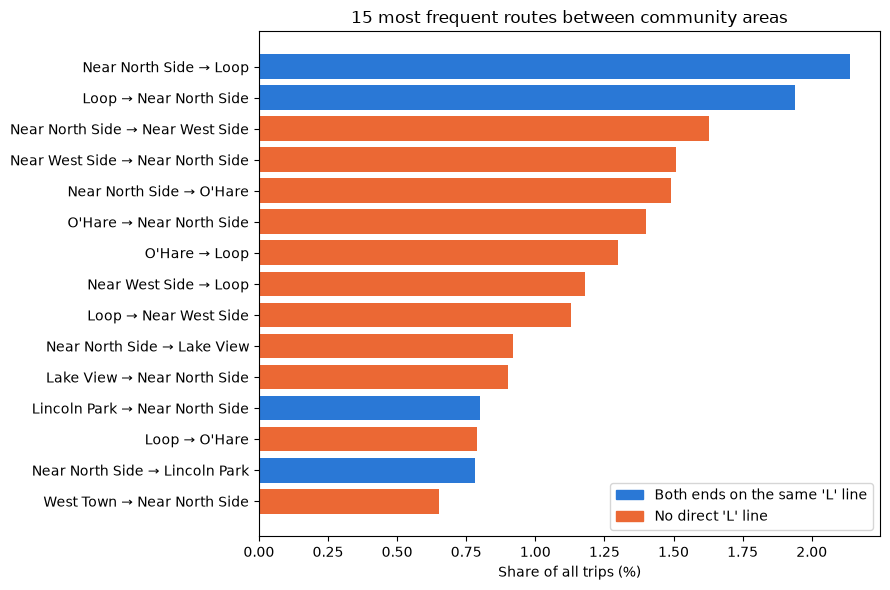

In [4]:
t15 = between.head(15).iloc[::-1]
labels = t15["from_name"] + " → " + t15["to_name"]
colors = ["#2a78d6" if c else "#eb6834" for c in t15["L_connected"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels, t15["share_pct"], color=colors)
ax.set_xlabel("Share of all trips (%)")
ax.set_title("15 most frequent routes between community areas")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a78d6", label="Both ends on the same 'L' line"),
                   Patch(color="#eb6834", label="No direct 'L' line")], loc="lower right")
plt.tight_layout()
plt.savefig(FIGS / "top_routes.png", dpi=150, bbox_inches="tight")
plt.show()

TODO (Harsh): 2–3 sentences. How many of the busiest routes could be done on one 'L' line? Which busy routes have no direct 'L' line? These are the first transit-gap candidates.

## Association rules: when and how far

In [5]:
# Rules that predict a destination from an origin (plus time, day or distance)
r = rules.copy()
route_rules = r[r["then_item"].str.startswith("to=") & r["if_items"].str.contains("from=")].copy()
route_rules["from_area"] = route_rules["if_items"].str.extract(r"from=(\d+)")[0].astype(int)
route_rules["to_area"] = route_rules["then_item"].str.extract(r"to=(\d+)")[0].astype(int)
route_rules = route_rules[route_rules["from_area"] != route_rules["to_area"]]
route_rules["route"] = route_rules["from_area"].map(names) + " → " + route_rules["to_area"].map(names)
print(len(route_rules), "rules predict a different destination area")
route_rules.sort_values("lift", ascending=False).head(15)[
    ["if_items", "then_item", "route", "support", "confidence", "lift"]].round(3)

281 rules predict a different destination area


,if_items,then_item,route,support,confidence,lift
70,day=weekday + dist=10+mi + from=22,to=76,Logan Square → O'Hare,0.002,0.740,11.119
71,day=weekday + dist=10+mi + from=7,to=76,Lincoln Park → O'Hare,0.004,0.738,11.085
72,dist=10+mi + from=22,to=76,Logan Square → O'Hare,0.002,0.735,11.036
73,dist=10+mi + from=7,to=76,Lincoln Park → O'Hare,0.004,0.733,11.010
74,dist=10+mi + from=6 + time=midday,to=76,Lake View → O'Hare,0.002,0.733,11.006
75,day=weekday + dist=10+mi + from=6 + time=midday,to=76,Lake View → O'Hare,0.002,0.733,11.006
80,dist=10+mi + from=8 + time=night,to=76,Near North Side → O'Hare,0.003,0.721,10.834
81,day=weekday + dist=10+mi + from=8 + time=night,to=76,Near North Side → O'Hare,0.003,0.721,10.834
82,day=weekday + dist=10+mi + from=32,to=56,Loop → Garfield Ridge,0.003,0.190,10.746
85,dist=10+mi + from=32,to=56,Loop → Garfield Ridge,0.003,0.188,10.637


In [6]:
# Rules about time of day and day of week (for example: airport trips and late-night trips)
context = r[r["then_item"].str.startswith(("time=", "day="))]
context.sort_values("lift", ascending=False).head(15)[["if_items", "then_item", "support", "confidence", "lift"]].round(3)

,if_items,then_item,support,confidence,lift
129,dist=10+mi + from=76 + time=late,day=weekend,0.003,0.210,7.711
132,from=76 + time=late,day=weekend,0.004,0.202,7.447
133,dist=10+mi + time=late,day=weekend,0.006,0.190,7.001
136,time=late + to=6,day=weekend,0.002,0.184,6.763
141,dist=5-10mi + time=late,day=weekend,0.006,0.159,5.858
146,time=late,day=weekend,0.027,0.153,5.625
158,day=weekend + to=8,time=late,0.004,1.000,5.625
157,day=weekend + dist=10+mi,time=late,0.006,1.000,5.625
156,day=weekend + from=8,time=late,0.003,1.000,5.625
155,day=weekend + from=28,time=late,0.002,1.000,5.625


TODO (Harsh): 3–4 sentences. Explain one or two rules in plain words (for example: "if a trip starts at O'Hare on a weekend, it goes to the Near North Side x% of the time, y times more often than average"). What do support, confidence and lift each tell us here?

## What this means for the project

TODO (Harsh): 2–3 bullets. Which routes should we look at as transit gaps? How will these routes feed the transit-gap score in Sprint 3?